# B3 — Exploring the review data

Goal: describe the data in five sentences and know what cleaning is needed before
the taxonomy (B4) and the gold set (B5).

Only aggregates get printed in this notebook. Raw review text stays out of the
committed outputs.

## 1. Load the reviews

In [105]:
import pandas as pd

from support_reply_gap.db import get_connection

In [106]:
# Read from the view, not the raw table: it already flags edited reviews and
# computes latency, so the notebook doesn't redefine those rules.
# The cast is needed because Postgres returns the latency as numeric, which
# pandas would store as slow Python Decimal objects.
QUERY = """
select
    review_id,
    app_key,
    score,
    content,
    posted_at,
    reply_content,
    replied_at,
    thumbs_up,
    app_version,
    scraped_at,
    likely_edited,
    reply_latency_hours::float8 as reply_latency_hours
from reviews_analysis
"""

with get_connection() as conn:
    cur = conn.execute(QUERY)
    columns = [col.name for col in cur.description]
    df = pd.DataFrame(cur.fetchall(), columns=columns)

df.shape

(21197, 12)

In [107]:
df.dtypes

review_id                                  str
app_key                                    str
score                                    int64
content                                    str
posted_at              datetime64[us, Etc/UTC]
reply_content                              str
replied_at             datetime64[us, Etc/UTC]
thumbs_up                                int64
app_version                                str
scraped_at             datetime64[us, Etc/UTC]
likely_edited                             bool
reply_latency_hours                    float64
dtype: object

## 2. Basic shape

How many reviews per app, over what time span, and which columns have gaps.

In [108]:
by_app = df.groupby("app_key").agg(
    rows=("review_id", "size"),
    first_review=("posted_at", "min"),
    last_review=("posted_at", "max"),
    last_scraped=("scraped_at", "max"),
)
by_app["days_covered"] = (by_app["last_review"] - by_app["first_review"]).dt.days
by_app["reviews_per_day"] = (by_app["rows"] / by_app["days_covered"]).round(1)
by_app

,rows,first_review,last_review,last_scraped,days_covered,reviews_per_day
app_key,,,,,,
c24,2881,2024-11-03 17:15:42+00:00,2026-11-02 14:54:54+00:00,2026-11-03 16:38:59.225722+00:00,728,4.0
n26,3289,2024-11-03 22:55:40+00:00,2026-11-02 11:29:53+00:00,2026-11-03 16:36:47.489198+00:00,728,4.5
revolut,15027,2024-11-03 18:22:34+00:00,2026-11-02 17:28:35+00:00,2026-11-03 16:38:38.483294+00:00,728,20.6


In [109]:
# Count and share side by side: 30 missing is noise in 21k rows, 30% is not.
missing = pd.DataFrame(
    {
        "missing": df.isna().sum(),
        "share": df.isna().mean().round(3),
    }
)
missing

,missing,share
review_id,0,0.000
app_key,0,0.000
score,0,0.000
content,0,0.000
posted_at,0,0.000
reply_content,16621,0.784
replied_at,16621,0.784
thumbs_up,0,0.000
app_version,2480,0.117
scraped_at,0,0.000


## 3. Score distribution

The star mix per app. It decides how the gold set (B5) has to be stratified, and it
is the denominator for reply rate by score later on.

In [110]:
score_counts = pd.crosstab(df["app_key"], df["score"], margins=True, margins_name="all")
# Shares per row, so apps of very different size can be compared directly.
score_shares = pd.crosstab(df["app_key"], df["score"], normalize="index").round(3)

display(score_counts)
score_shares

score,1,2,3,4,5,all
app_key,,,,,,
c24,437,145,153,236,1910,2881
n26,1041,180,183,234,1651,3289
revolut,1428,171,220,1045,12163,15027
all,2906,496,556,1515,15724,21197


score,1,2,3,4,5
app_key,,,,,
c24,0.152,0.050,0.053,0.082,0.663
n26,0.317,0.055,0.056,0.071,0.502
revolut,0.095,0.011,0.015,0.070,0.809


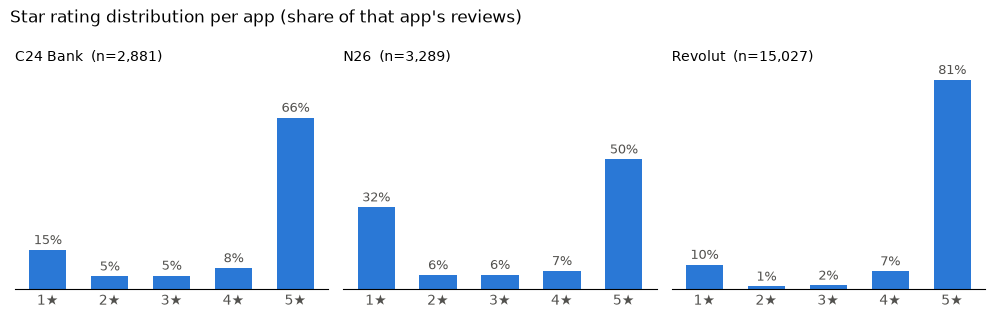

In [111]:
import matplotlib.pyplot as plt

from support_reply_gap.apps import by_key

BAR_COLOR = "#2a78d6"
INK = "#52514e"

# One panel per app on a shared scale: comparing shapes is the point, and one colour
# avoids implying the apps are a series to be read against each other.
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, (app_key, row) in zip(axes, score_shares.iterrows()):
    bars = ax.bar(row.index, row.values * 100, width=0.6, color=BAR_COLOR)
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9, color=INK)
    n = score_counts.loc[app_key, "all"]
    ax.set_title(f"{by_key(app_key).label}  (n={n:,})", loc="left", fontsize=10)
    ax.set_xticks([1, 2, 3, 4, 5], ["1★", "2★", "3★", "4★", "5★"])
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(colors=INK, length=0)

fig.suptitle("Star rating distribution per app (share of that app's reviews)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 4. Review length

How much text there is to classify, per app and per star rating. Lengths are heavily
skewed, so this uses percentiles and medians rather than means.

In [112]:
df["n_chars"] = df["content"].str.len()
# Whitespace split works for any language. German compounds pack more meaning into
# one word, so characters are the main measure and words are only a rough guide.
df["n_words"] = df["content"].str.split().str.len()

length_by_app = df.groupby("app_key")["n_chars"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
length_by_app["median_words"] = df.groupby("app_key")["n_words"].median()
length_by_app.round(0)

,count,mean,std,min,10%,25%,50%,75%,90%,max,median_words
app_key,,,,,,,,,,,
c24,2881.0,128.0,137.0,1.0,13.0,28.0,68.0,177.0,367.0,500.0,10.0
n26,3289.0,152.0,153.0,1.0,12.0,30.0,90.0,233.0,433.0,500.0,14.0
revolut,15027.0,73.0,105.0,1.0,5.0,12.0,30.0,80.0,205.0,680.0,5.0


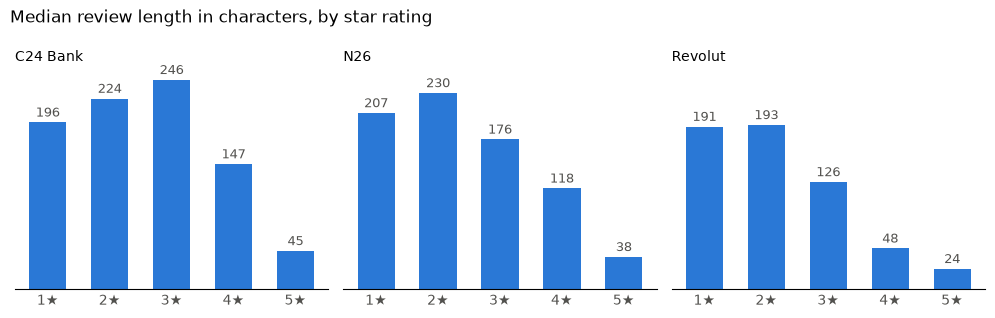

In [113]:
median_chars = df.pivot_table(index="app_key", columns="score", values="n_chars", aggfunc="median")

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, (app_key, row) in zip(axes, median_chars.iterrows()):
    bars = ax.bar(row.index, row.values, width=0.6, color=BAR_COLOR)
    ax.bar_label(bars, fmt="%.0f", padding=2, fontsize=9, color=INK)
    ax.set_title(by_key(app_key).label, loc="left", fontsize=10)
    ax.set_xticks([1, 2, 3, 4, 5], ["1★", "2★", "3★", "4★", "5★"])
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(colors=INK, length=0)

fig.suptitle("Median review length in characters, by star rating", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 5. Reviews without real content

Three flags, from strictest to loosest:

- `no_letters`: emoji or punctuation only
- `one_word`: a single word
- `under_20_chars`: a length cut-off, shown only for comparison

In [114]:
# [^\W\d_] means "a word character that is not a digit or underscore", i.e. any
# Unicode letter. A plain [a-zA-Z] would miss umlauts and ß.
has_letter = df["content"].str.contains(r"[^\W\d_]", regex=True)
df["no_letters"] = ~has_letter
df["one_word"] = has_letter & (df["n_words"] == 1)
df["under_20_chars"] = df["n_chars"] < 20

FLAGS = ["no_letters", "one_word", "under_20_chars"]
display(df[FLAGS].sum().rename("reviews"))
display(df.groupby("app_key")[FLAGS].mean().round(3))
df.groupby("score")[FLAGS].mean().round(3)

no_letters         219
one_word          2326
under_20_chars    6805
Name: reviews, dtype: int64

,no_letters,one_word,under_20_chars
app_key,,,
c24,0.002,0.041,0.163
n26,0.006,0.043,0.173
revolut,0.013,0.137,0.384


,no_letters,one_word,under_20_chars
score,,,
1,0.000,0.009,0.031
2,0.002,0.010,0.018
3,0.002,0.014,0.065
4,0.007,0.083,0.233
5,0.013,0.138,0.402


## 6. Language mix

Detected with `lingua`, which runs offline and copes better with short texts than
most detectors. Two settings matter:

- **A restricted candidate list.** With all 75 languages, short German praise like
  "Top Bank 👍" comes out as Slovene or Latin. The list below covers German, English
  and the languages most widely spoken by people living in Germany.
- **A confidence threshold.** Below 0.7 the result is marked `uncertain` instead of
  trusted. These are mostly one- or two-word reviews.

In [115]:
from lingua import Language, LanguageDetectorBuilder

CANDIDATE_LANGUAGES = [
    Language.GERMAN, Language.ENGLISH, Language.TURKISH, Language.RUSSIAN,
    Language.UKRAINIAN, Language.POLISH, Language.ARABIC, Language.ROMANIAN,
    Language.ITALIAN, Language.SPANISH, Language.FRENCH, Language.CROATIAN,
    Language.BOSNIAN, Language.SERBIAN, Language.BULGARIAN, Language.PERSIAN,
    Language.PORTUGUESE, Language.DUTCH, Language.GREEK,
]  # fmt: skip
MIN_CONFIDENCE = 0.7

detector = LanguageDetectorBuilder.from_languages(*CANDIDATE_LANGUAGES).build()

# Takes about 30 seconds for 21k reviews.
results = detector.compute_language_confidence_values_in_parallel(df["content"].tolist())
# Each result is sorted best-first, so [0] is the most likely language.
df["lang"] = [r[0].language.name.lower() for r in results]
df["lang_confidence"] = [r[0].value for r in results]
df.loc[df["lang_confidence"] < MIN_CONFIDENCE, "lang"] = "uncertain"

In [116]:
# Fold the long tail into "other" so the tables stay readable.
df["lang_group"] = df["lang"].where(df["lang"].isin(["german", "english", "uncertain"]), "other")
LANG_ORDER = ["german", "english", "other", "uncertain"]

display(df["lang"].value_counts().rename("reviews"))
display(pd.crosstab(df["app_key"], df["lang_group"], normalize="index")[LANG_ORDER].round(3))
pd.crosstab(df["score"], df["lang_group"], normalize="index")[LANG_ORDER].round(3)

lang
german        14722
uncertain      6018
english         358
spanish          16
russian          16
polish           14
turkish          11
french           11
arabic            8
italian           7
romanian          4
ukrainian         3
dutch             2
bosnian           2
greek             2
persian           1
bulgarian         1
portuguese        1
Name: reviews, dtype: int64

lang_group,german,english,other,uncertain
app_key,,,,
c24,0.862,0.003,0.001,0.134
n26,0.828,0.013,0.003,0.156
revolut,0.633,0.020,0.006,0.341


lang_group,german,english,other,uncertain
score,,,,
1,0.917,0.056,0.003,0.024
2,0.958,0.022,0.000,0.020
3,0.917,0.023,0.007,0.052
4,0.776,0.019,0.008,0.197
5,0.629,0.009,0.005,0.357


## 7. Reply rate by star rating

The share of reviews that have a company reply, per app and star rating. This is the
dependent variable of the whole project, so every rate is shown next to its count.
Descriptive only: which reviews get a reply is the company's choice, and the reasons
for it are not observed.

In [117]:
df["replied"] = df["replied_at"].notna()

reply_rate = df.pivot_table(index="app_key", columns="score", values="replied", aggfunc="mean")
reply_rate["all"] = df.groupby("app_key")["replied"].mean()
# Reply counts next to the rates: 86% of 30 reviews and 86% of 1,400 are not equally solid.
reply_count = df.pivot_table(index="app_key", columns="score", values="replied", aggfunc="sum")
reply_count["all"] = df.groupby("app_key")["replied"].sum()

display(reply_count)
reply_rate.round(3)

score,1,2,3,4,5,all
app_key,,,,,,
c24,158,55,52,17,25,307
n26,885,155,153,199,1318,2710
revolut,1229,132,136,28,34,1559


score,1,2,3,4,5,all
app_key,,,,,,
c24,0.362,0.379,0.340,0.072,0.013,0.107
n26,0.850,0.861,0.836,0.850,0.798,0.824
revolut,0.861,0.772,0.618,0.027,0.003,0.104


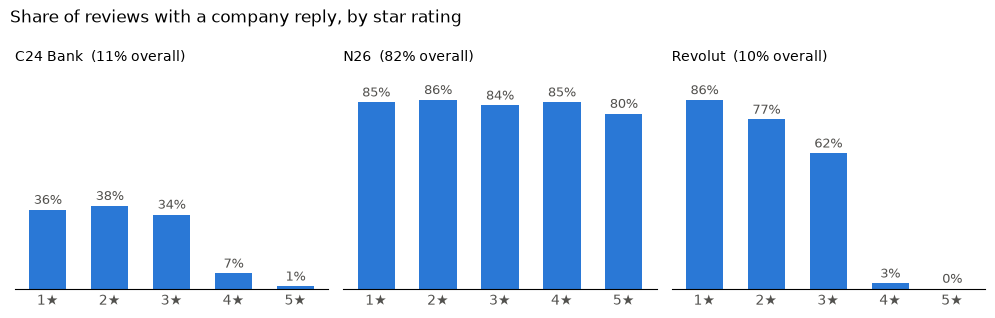

In [118]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, (app_key, row) in zip(axes, reply_rate.drop(columns="all").iterrows()):
    bars = ax.bar(row.index, row.values * 100, width=0.6, color=BAR_COLOR)
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9, color=INK)
    overall = reply_rate.loc[app_key, "all"]
    ax.set_title(f"{by_key(app_key).label}  ({overall:.0%} overall)", loc="left", fontsize=10)
    ax.set_xticks([1, 2, 3, 4, 5], ["1★", "2★", "3★", "4★", "5★"])
    ax.set_yticks([])
    ax.set_ylim(0, 100)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(colors=INK, length=0)

fig.suptitle("Share of reviews with a company reply, by star rating", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 8. Reply rate and latency over time

Two questions:

1. **Is reply behaviour stable across the window?** If an app changed how it
   replies, pooling two years mixes two regimes.
2. **Are the newest reviews missing replies only because they are new?** A review
   from yesterday has had less time to get a reply, which would understate the
   reply rate at the end of the window.

Reply rate over time uses 1–2★ reviews only. The star mix shifts from month to
month, and step 7 showed that star rating strongly affects reply rate.

In [119]:
low_star = df[df["score"] <= 2].copy()
# Drop the timezone first: monthly periods have no timezone, and pandas warns otherwise.
low_star["month"] = low_star["posted_at"].dt.tz_localize(None).dt.to_period("M")
# The scrape ran on 3 November, so November only has two days of reviews.
low_star = low_star[low_star["month"] < pd.Period("2026-11", "M")]

monthly_rate = low_star.pivot_table(
    index="month", columns="app_key", values="replied", aggfunc="mean"
)
monthly_n = low_star.pivot_table(index="month", columns="app_key", values="replied", aggfunc="size")

display(monthly_n)
monthly_rate.round(2)

app_key,c24,n26,revolut
month,,,
2024-11,19,72,56
2024-12,16,85,71
2025-01,23,60,76
2025-02,26,28,49
2025-03,28,49,52
2025-04,24,35,39
2025-05,14,56,53
2025-06,11,55,56
2025-07,17,62,101


app_key,c24,n26,revolut
month,,,
2024-11,0.21,0.17,0.96
2024-12,0.06,0.72,0.85
2025-01,0.04,0.77,0.75
2025-02,0.00,0.11,0.86
2025-03,0.25,0.06,0.96
2025-04,0.04,0.71,0.90
2025-05,0.00,1.00,0.89
2025-06,0.00,1.00,0.96
2025-07,0.06,1.00,0.91


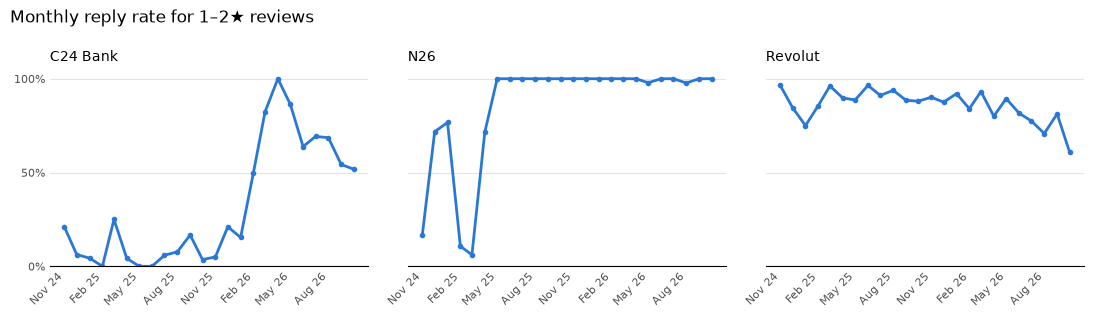

In [120]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, app_key in zip(axes, monthly_rate.columns):
    series = monthly_rate[app_key]
    x = series.index.to_timestamp()
    ax.plot(x, series.values * 100, color=BAR_COLOR, linewidth=2, marker="o", markersize=3)
    ax.set_title(by_key(app_key).label, loc="left", fontsize=10)
    ax.set_ylim(0, 105)
    ax.set_yticks([0, 50, 100], ["0%", "50%", "100%"])
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(colors=INK, length=0, labelsize=8)
    # Quarterly ticks: monthly labels would overlap at this width.
    ax.set_xticks(x[::3], [p.strftime("%b %y") for p in x[::3]], rotation=45, ha="right")

fig.suptitle("Monthly reply rate for 1–2★ reviews", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [121]:
replied = df[df["reply_latency_hours"].notna()].copy()

# How long it takes until most replies have arrived. The tail matters for the
# cut-off below, so this goes up to the 99th percentile.
latency_pct = replied.groupby("app_key")["reply_latency_hours"].quantile([0.5, 0.9, 0.95, 0.99])
display((latency_pct.unstack() / 24).round(1).add_suffix(" (days)"))

replied["quarter"] = replied["posted_at"].dt.tz_localize(None).dt.to_period("Q")
replied.pivot_table(
    index="quarter", columns="app_key", values="reply_latency_hours", aggfunc="median"
).round(1)

,0.5 (days),0.9 (days),0.95 (days),0.99 (days)
app_key,,,,
c24,3.1,8.5,11.4,18.5
n26,0.8,7.4,12.6,28.0
revolut,0.0,0.1,0.3,1.1


app_key,c24,n26,revolut
quarter,,,
2024Q4,29.5,234.2,0.4
2025Q1,65.3,18.9,0.5
2025Q2,59.7,68.4,0.4
2025Q3,71.6,23.0,0.5
2025Q4,249.0,25.5,0.5
2026Q1,120.3,49.8,0.4
2026Q2,104.0,7.8,0.4
2026Q3,54.6,1.6,0.4
2026Q4,89.3,2.5,0.5


In [122]:
# Age = how old the review was when it was scraped. If young reviews have a lower
# reply rate, it is because replies have not arrived yet, not because none will.
# Uses all 1–2★ reviews, including the partial November dropped above.
recent = df[df["score"] <= 2].copy()
recent["age_days"] = (recent["scraped_at"] - recent["posted_at"]).dt.total_seconds() / 86400
recent["age_bin"] = pd.cut(recent["age_days"], [0, 7, 14, 30, 60, 800])

recent.pivot_table(
    index="age_bin", columns="app_key", values="replied", aggfunc=["mean", "size"], observed=True
).round(2)

mean               size              
app_key     c24   n26 revolut  c24   n26 revolut
age_bin                                         
(0, 7]     0.00  1.00    0.80    8     9      20
(7, 14]    0.80  1.00    0.71    5    11      17
(14, 30]   0.58  1.00    0.52   31    27      61
(30, 60]   0.49  1.00    0.79   49    34      72
(60, 800]  0.34  0.84    0.87  489  1140    1429

## 9. Reply text diversity

Are replies written individually or taken from templates? If they are mostly
boilerplate, reply *text* carries no signal and the analysis should rely on reply
presence and timing only (see the risk notes in `docs/build-order.md`).

Exact matching undercounts templates: nearly every reply contains the reviewer's
name, an agent's name or a reference number. So replies are normalised first, and
the main measure is how often the **opening** (the first 8 words after the greeting)
is shared with other replies.

Replies contain customer names, so only aggregates are printed here.

In [123]:
import re

GREETING = re.compile(
    r"^\s*(hallo|hey|hi|hello|dear|liebe|lieber|guten tag|sehr geehrte\w*)\b[^,!\n]*[,!\n]"
)
SIGN_OFF = re.compile(r"(beste|viele|liebe) grüße.*$", flags=re.DOTALL)
# E-mails, links and any token with a digit (ticket and reference numbers).
VARIABLE_TOKENS = re.compile(r"\S+@\S+|https?://\S+|\S*\d\S*")


def normalise_reply(text: str) -> str:
    """Strip the parts of a reply that change per customer, keep the template."""
    text = text.lower()
    text = GREETING.sub(" ", text)  # "Hallo Max," -> the reviewer's name
    text = SIGN_OFF.sub(" ", text)  # "Beste Grüße, Anja vom ..." -> the agent's name
    text = VARIABLE_TOKENS.sub(" ", text)
    text = re.sub(r"[\W_]+", " ", text)
    return " ".join(text.split())


replies = df[df["replied"]].copy()
replies["normalised"] = replies["reply_content"].map(normalise_reply)
replies["opening"] = replies["normalised"].str.split().str[:8].str.join(" ")


def template_stats(group: pd.DataFrame) -> pd.Series:
    openings = group["opening"].value_counts()
    return pd.Series(
        {
            "replies": len(group),
            "distinct_exact": group["reply_content"].nunique() / len(group),
            "distinct_normalised": group["normalised"].nunique() / len(group),
            "opening_shared": (group["opening"].map(openings) > 1).mean(),
            "top5_openings": openings.head(5).sum() / len(group),
        }
    )


replies.groupby("app_key").apply(template_stats).round(3)

,replies,distinct_exact,distinct_normalised,opening_shared,top5_openings
app_key,,,,,
c24,307.0,1.000,0.674,0.717,0.410
n26,2710.0,0.955,0.714,0.741,0.145
revolut,1559.0,0.943,0.886,0.443,0.082


In [124]:
# Reply language next to review language. No confidence threshold here: replies
# are long (median ~250 characters), so detection is reliable.
reply_results = detector.compute_language_confidence_values_in_parallel(
    replies["reply_content"].tolist()
)
replies["reply_lang"] = [r[0].language.name.lower() for r in reply_results]
replies["reply_lang"] = replies["reply_lang"].where(
    replies["reply_lang"].isin(["german", "english"]), "other"
)

pd.crosstab([replies["app_key"], replies["lang_group"]], replies["reply_lang"])

reply_lang          english  german  other
app_key lang_group                        
c24     english           0       3      0
        german            0     299      0
        uncertain         0       5      0
n26     english          35       2      0
        german            1    2298      0
        other             0       0      4
        uncertain        87     282      1
revolut english         122       0      0
        german         1077     321      1
        other             8       0      2
        uncertain        25       3      0

## 10. Duplicates and spam

Two checks:

1. **Repeated texts.** The same review text under different review ids, after
   ignoring case and punctuation. Short praise like "Top" repeats naturally, so the
   table is split by length.
2. **Spike days.** Days with an unusual number of 1★ reviews. This catches both
   review bombing and real incidents, which have to be told apart by reading.

There is no author column, so "the same person posting many reviews" cannot be
checked.

In [125]:
df["normalised"] = df["content"].str.lower().str.replace(r"[\W_]+", " ", regex=True).str.strip()
df["text_repeats"] = df["normalised"].map(df["normalised"].value_counts())

df["length_band"] = pd.cut(
    df["n_words"], [0, 2, 4, 9, 1000], labels=["1–2 words", "3–4", "5–9", "10+"]
)
df.groupby("length_band", observed=True).agg(
    reviews=("review_id", "size"),
    in_repeated_text=("text_repeats", lambda s: (s > 1).sum()),
    share=("text_repeats", lambda s: (s > 1).mean().round(3)),
)

,reviews,in_repeated_text,share
length_band,,,
1–2 words,5386,4670,0.867
3–4,3428,1409,0.411
5–9,4239,201,0.047
10+,8144,2,0.000


In [126]:
one_star = df[df["score"] == 1].copy()
one_star["day"] = one_star["posted_at"].dt.date

daily = one_star.groupby(["app_key", "day"]).agg(
    one_star_reviews=("review_id", "size"), reply_rate=("replied", "mean")
)
# Compare each day with that app's typical day, since the apps differ a lot in volume.
# Days without any 1★ review are not in the grouping, so "typical" is slightly high.
daily["typical_day"] = daily.groupby("app_key")["one_star_reviews"].transform("median")
daily["times_typical"] = daily["one_star_reviews"] / daily["typical_day"]

daily.sort_values("times_typical", ascending=False).groupby("app_key").head(3).round(2)

one_star_reviews  reply_rate  typical_day  times_typical
app_key day                                                                 
revolut 2026-10-20                24        0.12          2.0           12.0
c24     2026-09-30                11        0.36          1.0           11.0
        2026-04-08                 6        1.00          1.0            6.0
        2026-10-01                 5        0.60          1.0            5.0
n26     2025-11-18                10        1.00          2.0            5.0
        2025-03-14                 8        0.12          2.0            4.0
        2024-12-23                 8        1.00          2.0            4.0
revolut 2025-07-17                 8        0.88          2.0            4.0
        2025-07-11                 7        0.57          2.0            3.5

## 11. Summary

1. The dataset holds 21,197 Google Play reviews of N26, Revolut and C24 Bank posted
   between November 2024 and November 2026. Revolut makes up 71% of all reviews but
   only 47% of the 1–2★ ones.
2. Ratings are J-shaped (74% are 5★). Complaints sit in 1–3★ with a median of about
   200 characters, while praise is often a single word such as "Top" or "Super".
3. The text is overwhelmingly German. About 5% of 1–2★ reviews are clearly in another
   language, mostly English, and very short reviews cannot be language-tagged
   reliably.
4. Reply behaviour differs by app and changes over time. N26 has replied to almost
   every 1–2★ review since May 2025, Revolut replies to about 86% of 1★ reviews
   within an hour (mostly in English), and C24 went from about 5% to 50–70% of 1–2★
   reviews from February 2026.
5. Replies are templates with names filled in, so the analysis relies on whether and
   how fast a reply arrives, not on its text. There is no sign of spam, but incident
   days (for example a Revolut outage on 20 October 2026) concentrate complaints and
   reply behaviour in a single day.

## Cleaning and analysis decisions

Nothing is deleted from the database. Every rule below is a filter applied where it
is needed, so the raw data stays complete and each rule can be reversed.

| # | Rule | Applies to | Why | Status |
|---|---|---|---|---|
| 1 | Keep only reviews detected as German or `uncertain` | Gold set, classifier | German stopwords in the baseline; 5% of complaints lost, noted as a limitation | Decided |
| 2 | Leave out emoji-only and one-word reviews when sampling | Gold set | Almost all `no_complaint`; labelling them wastes effort. They stay in the data | Decided |
| 3 | Stratify by app × star rating; cap reviews per app and day | Gold set | Random sampling is ~74% 5★; one incident would dominate a class | Decided |
| 4 | Exclude reviews younger than 30 days | Reply analysis | 99% of replies arrive within 28 days; younger reviews understate the reply rate | Decided |
| 5 | Report results with and without spike days | Reply analysis | One outage day moves Revolut's 1★ reply rate from ~86% to 12% | Decided |
| 6 | Always compare within star rating | Reply analysis | Reply rate depends strongly on stars for C24 and Revolut | Decided |
| 7 | Use reply presence and latency, not reply text | Reply analysis | Replies are templates with names filled in | Decided |
| 8 | Latency only where the review was not edited after the reply | Reply analysis | Already handled by the `reviews_analysis` view | Decided |
| 9 | Analysis window: common stable window vs full window split by period | Reply analysis | N26 and C24 changed reply behaviour within the window | Open — decide in C2 |

Limitations for the README: Google caps reviews at 500 characters (1.5% hit the cap),
only the reply visible at scrape time is observed, and there is no author field, so
repeat posters cannot be detected.